# ARES+MOOG metallicities: results and tests

[Fe/H] from the equivalent-width method that SWEET-Cat and most of the planet-host literature use (ARES equivalent
widths, MOOG + Kurucz ATLAS9, Fe I/Fe II excitation and ionisation balance, run through FASMA; `hpc/ew_pipeline.py`,
`hpc/ares_moog/README.md`). This notebook replaces the PHOENIX-fit [Fe/H] of `Metallicity_Survey.ipynb` with a method
that is directly comparable to published values, so the first job is to test it against published values **obtained
with the same method**:

1. **Fit outcomes:** which co-adds give a usable fit, by instrument.
2. **Validation stars:** four recent HARPS ARES+MOOG analyses, reproduced from the same archive spectra.
3. **SWEET-Cat:** the homogeneous ARES+MOOG catalogue (`SWFlag = 1`), for every star in common.
4. **EBLM literature:** the published ARES+MOOG [Fe/H] of EBLM primaries (EBLM VIII, IX, XI).
5. **SOPHIE:** why SOPHIE HE (and HR) read low, and whether the offset correction fixes it.
6. **Results:** hot-Jupiter hosts vs. EBLM primaries, and ARES+MOOG vs. the PHOENIX fit.

Inputs (all in `metallicity_hpc_data/`, synced from the cluster): `results/ew_fits.csv` (free fits, one per co-add),
`results/ew_fits_fixlogg.csv` (logg fixed at TIC), `results/feh_candidates.csv` (every usable fit, offsets applied),
`results/feh_adopted.csv` (one [Fe/H] per star), `results/feh_offsets.csv`, and `ew_validation_results/`.

In [1]:
import os, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from astropy.coordinates import SkyCoord
import astropy.units as u

METAL_ROOT = os.environ.get('METAL_ROOT', 'metallicity_hpc_data')
RES, CAT, D = f'{METAL_ROOT}/results', f'{METAL_ROOT}/catalogs', 'eblm_metallicity_data'
VAL = f'{METAL_ROOT}/ew_validation_results'

plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.color': '#e6e5e0', 'grid.linewidth': 0.8,
                     'axes.edgecolor': '#898781', 'axes.axisbelow': True, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 10.5, 'legend.frameon': False})
# same fixed categorical slots as Metallicity_Survey.ipynb
COL = {'EBLM': '#2a78d6', 'HJ': '#eb6834', 'alt': '#1baf7a', 'alt2': '#eda100', 'ink': '#52514e', 'mute': '#c3c2b7'}
SAMPLE_LABEL = {'HJ': 'Hot-Jupiter hosts', 'EBLM': 'EBLM primaries'}
# three instrument groups, in a fixed order and color, used in every plot
GROUPS = ['ESO', 'SOPHIE HR', 'SOPHIE HE']
GCOL = {'ESO': COL['EBLM'], 'SOPHIE HR': COL['alt'], 'SOPHIE HE': COL['HJ']}
INSTS = ['HARPS', 'ESPRESSO', 'UVES', 'FEROS', 'SOPHIE HR', 'SOPHIE HE']
TEFF = (5300, 7000)       # comparison range used in Metallicity_Survey.ipynb

def inst_of(mode):        # 'SOPHIE_HE_R39000' -> 'SOPHIE HE'; 'UVES_R57000' -> 'UVES'
    return re.sub(r'_R\d+$', '', mode).replace('_', ' ')

def group_of(inst):
    return inst if inst.startswith('SOPHIE') else 'ESO'

def robust_std(x):
    x = np.asarray(x, float); x = x[np.isfinite(x)]
    return 1.4826 * np.median(np.abs(x - np.median(x))) if x.size else np.nan

def one_to_one(ax, lo=-0.9, hi=0.6):
    ax.plot([lo, hi], [lo, hi], color=COL['ink'], lw=1, ls='--', zorder=0)
    ax.set_xlim(lo, hi); ax.set_ylim(lo, hi); ax.set_aspect('equal')

def summary(d, by):
    # median offset, its error, robust scatter and normalised scatter of a column of differences 'd'
    g = d.groupby(by, sort=False)
    out = pd.DataFrame({'n': g.d.size(), 'median Δ': g.d.median(),
                        'error': g.d.apply(lambda x: 1.2533 * robust_std(x) / np.sqrt(len(x))),
                        'robust rms': g.d.apply(robust_std)})
    if 'z' in d:
        out['robust rms / σ'] = g.z.apply(robust_std)
    return out

# --- the pipeline tables
ew = pd.read_csv(f'{RES}/ew_fits.csv')
fix = pd.read_csv(f'{RES}/ew_fits_fixlogg.csv')
cand = pd.read_csv(f'{RES}/feh_candidates.csv')
adopt = pd.read_csv(f'{RES}/feh_adopted.csv')
offsets = pd.read_csv(f'{RES}/feh_offsets.csv')
val = pd.read_csv(f'{VAL}/ew_validation.csv')
targets = pd.read_csv(f'{CAT}/targets.csv').drop_duplicates('target_id')
phoenix = pd.read_csv(f'{RES}/metallicity_final.csv')        # the PHOENIX-fit [Fe/H] of Metallicity_Survey.ipynb
for t in (ew, fix, cand):
    t['mode'] = t.group.str.split('__').str[1]
    t['inst'] = t['mode'].map(inst_of)
adopt['mode'] = adopt['inst']
adopt['inst'] = adopt['mode'].map(inst_of)
adopt['group'] = adopt.inst.map(group_of)
adopt['flag_list'] = adopt['flags'].fillna('').str.split(';').map(lambda f: [x for x in f if x])
if 'vbroad' not in adopt:   # feh_adopted.csv from before the vbroad column was added: take it from the PHOENIX fits
    adopt = adopt.merge(phoenix[['target_id', 'vbroad']], on='target_id', how='left')

# --- SWEET-Cat, matched by coordinates (5")
sc = pd.read_csv(f'{D}/sweetcat.csv').dropna(subset=['RA', 'DEC', '[Fe/H]'])
c_sc = SkyCoord(sc.RA.values, sc.DEC.values, unit=(u.hourangle, u.deg))
c_t = SkyCoord(targets.ra.values * u.deg, targets.dec.values * u.deg)
idx, sep, _ = c_t.match_to_catalog_sky(c_sc)
hit = sep.arcsec < 5
sc_cols = {'[Fe/H]': 'sc_feh', 'e[Fe/H]': 'sc_feh_err', 'Teff': 'sc_teff', 'Logg': 'sc_logg', 'SWFlag': 'sc_homog',
           'Vt': 'sc_vt', 'Reference': 'sc_ref', 'Name': 'sc_name'}
for src, dst in sc_cols.items():
    targets[dst] = np.where(hit, sc[src].values[idx], np.nan)
targets.loc[~hit, ['sc_ref', 'sc_name']] = None

print(f'{ew.target_id.nunique()} stars / {len(ew)} co-adds fitted; {len(adopt)} stars adopted '
      f"({adopt['sample'].value_counts().to_dict()})")
print(f'SWEET-Cat matches: {hit.sum()} of {len(targets)} targets, {np.nansum(targets.sc_homog == 1)} homogeneous')

587 stars / 786 co-adds fitted; 513 stars adopted ({'HJ': 316, 'EBLM': 197})
SWEET-Cat matches: 615 of 1490 targets, 296 homogeneous


## 1. Fit outcomes

Every co-add is first fitted with Teff, logg, ξ and [Fe/H] free. A free fit is usable only if FASMA converged and
logg did not run to the grid edge (logg = 5, which happens when too few or biased Fe II lines drive the ionisation
balance). The `rescue` stage re-fits everything else with logg fixed at the TIC value. The
adopted value applies a small measured correction for fixing logg (HARPS fixed − free, below).

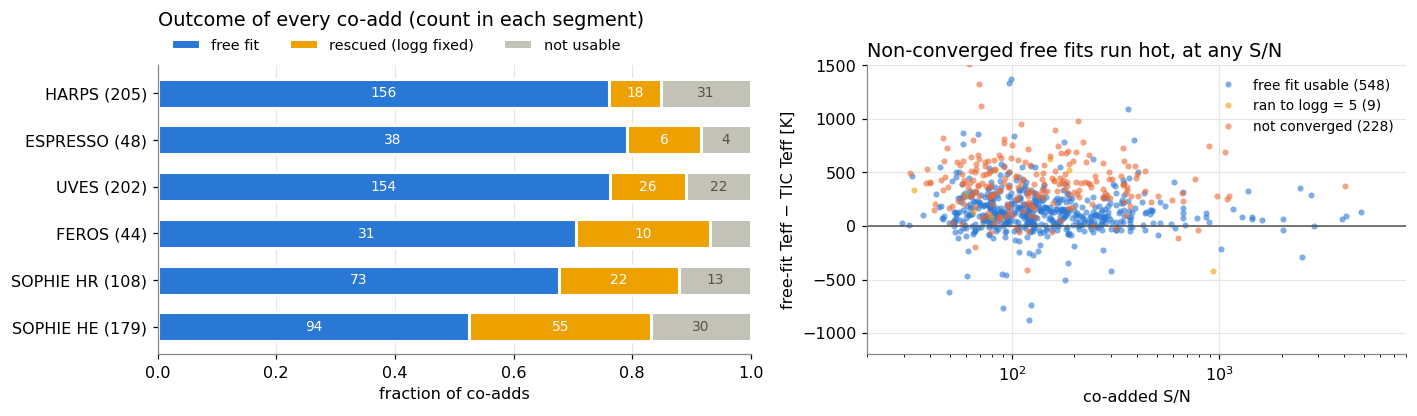

free-fit problems by instrument (co-adds):


free_problem,error,logg = 5,not converged,ok
inst,,,,
HARPS,0,3,45,157
ESPRESSO,0,1,9,38
UVES,0,0,48,154
FEROS,0,0,13,31
SOPHIE HR,0,1,33,74
SOPHIE HE,1,4,80,94


stars with no usable fit at all: 74 (+ 0 usable but excluded)


In [2]:
used = cand.set_index('group').method
ew['outcome'] = ew.group.map(used).map({'free': 'free fit', 'fixlogg': 'rescued (logg fixed)'}).fillna('not usable')
conv = ew.converged.astype('boolean').fillna(False).astype(bool)   # NaN for the one co-add whose fit crashed
why = np.select([ew.status.str.startswith('failed'), ~conv, ew.logg >= 4.99], ['error', 'not converged', 'logg = 5'], 'ok')
ew['free_problem'] = why
OUT = ['free fit', 'rescued (logg fixed)', 'not usable']
OCOL = {'free fit': COL['EBLM'], 'rescued (logg fixed)': COL['alt2'], 'not usable': COL['mute']}

tab = pd.crosstab(ew.inst, ew.outcome).reindex(index=INSTS, columns=OUT).fillna(0).astype(int)
frac = tab.div(tab.sum(axis=1), axis=0)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 3.9), gridspec_kw={'width_ratios': [1.1, 1]})
y = np.arange(len(INSTS))[::-1]
left = np.zeros(len(INSTS))
for o in OUT:
    a1.barh(y, frac[o], left=left, height=0.62, color=OCOL[o], label=o, edgecolor='white', linewidth=2)
    for yy, l, f, n in zip(y, left, frac[o], tab[o]):
        if f > 0.08:
            a1.text(l + f / 2, yy, f'{n}', ha='center', va='center', fontsize=9, color='white' if o != 'not usable' else COL['ink'])
    left += frac[o].values
a1.set_yticks(y, [f'{i} ({n})' for i, n in zip(INSTS, tab.sum(axis=1))])
a1.set_xlim(0, 1); a1.set_xlabel('fraction of co-adds'); a1.grid(axis='y', visible=False)
a1.legend(ncol=3, loc='lower left', bbox_to_anchor=(0, 1.0), fontsize=9.5)
a1.set_title('Outcome of every co-add (count in each segment)', loc='left', pad=26)

# what went wrong with the free fits, against co-added S/N
for prob, col, lab in [('ok', COL['EBLM'], 'free fit usable'), ('logg = 5', COL['alt2'], 'ran to logg = 5'),
                       ('not converged', COL['HJ'], 'not converged')]:
    s = ew[ew.free_problem == prob]
    a2.plot(s.snr_coadd, s.teff - s.teff0, 'o', ms=4, alpha=0.6, color=col, mec='none', label=f'{lab} ({len(s)})')
a2.set_xscale('log'); a2.set_xlim(20, 8000); a2.axhline(0, color=COL['ink'], lw=1)
a2.set_xlabel('co-added S/N'); a2.set_ylabel('free-fit Teff − TIC Teff [K]'); a2.set_ylim(-1200, 1500)
a2.legend(fontsize=9, loc='upper right'); a2.set_title('Non-converged free fits run hot, at any S/N', loc='left')
plt.tight_layout(); plt.show()

print('free-fit problems by instrument (co-adds):')
display(pd.crosstab(ew.inst, ew.free_problem).reindex(INSTS))
print(f"stars with no usable fit at all: {ew.target_id.nunique() - cand.target_id.nunique()} "
      f"(+ {len(set(cand.target_id) - set(adopt.target_id))} usable but excluded)")

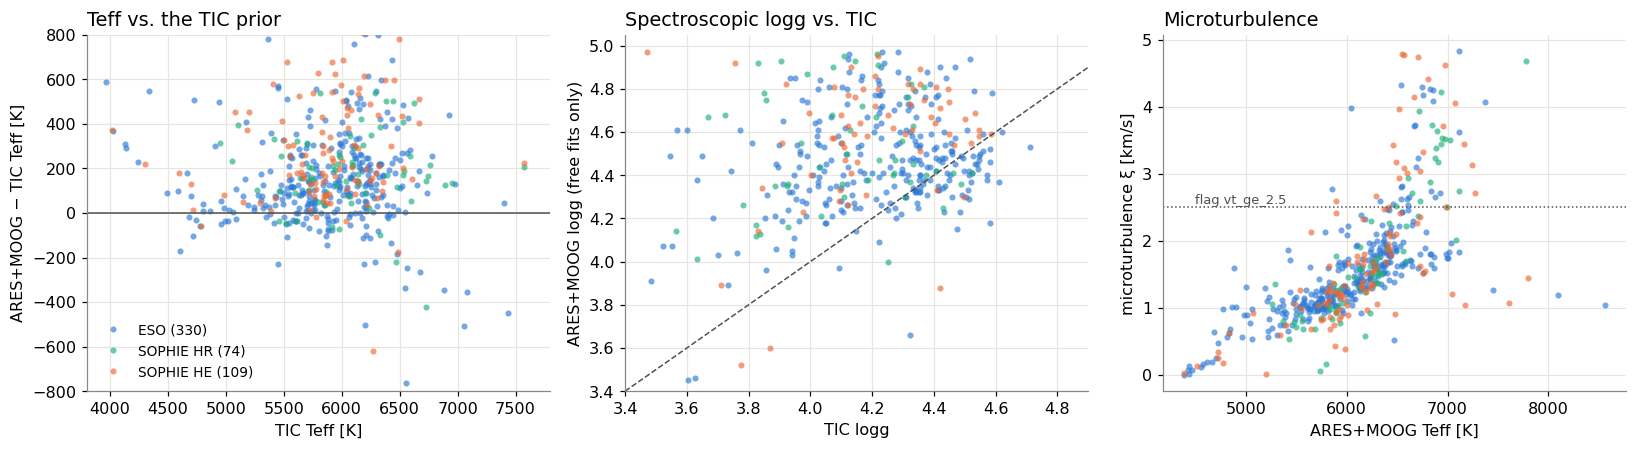

,group,robust rms ΔTeff [K],median ΔTeff [K],median Δlogg (free fits)
0,ESO,166.21,118.0,0.22
1,SOPHIE HR,134.92,183.0,0.41
2,SOPHIE HE,219.42,223.0,0.38


In [3]:
# parameters of the adopted fits against the TIC priors
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for g in GROUPS:
    s = adopt[adopt.group == g]
    fr = s[s.method == 'free']
    axes[0].plot(s.tic_teff, s.teff - s.tic_teff, 'o', ms=4, alpha=0.65, color=GCOL[g], mec='none', label=f'{g} ({len(s)})')
    axes[1].plot(fr.tic_logg, fr.logg, 'o', ms=4, alpha=0.65, color=GCOL[g], mec='none')
    axes[2].plot(s.teff, s.vt, 'o', ms=4, alpha=0.65, color=GCOL[g], mec='none')
axes[0].axhline(0, color=COL['ink'], lw=1); axes[0].set(xlabel='TIC Teff [K]', ylabel='ARES+MOOG − TIC Teff [K]', ylim=(-800, 800), xlim=(3800, 7800))
axes[0].legend(fontsize=9)
axes[1].plot([3.4, 5], [3.4, 5], color=COL['ink'], lw=1, ls='--')
axes[1].set(xlabel='TIC logg', ylabel='ARES+MOOG logg (free fits only)', xlim=(3.4, 4.9), ylim=(3.4, 5.05))
axes[2].axhline(2.5, color=COL['ink'], lw=1, ls=':'); axes[2].text(4500, 2.55, 'flag vt_ge_2.5', fontsize=8.5, color=COL['ink'])
axes[2].set(xlabel='ARES+MOOG Teff [K]', ylabel='microturbulence ξ [km/s]')
for ax, t in zip(axes, ['Teff vs. the TIC prior', 'Spectroscopic logg vs. TIC', 'Microturbulence']):
    ax.set_title(t, loc='left')
plt.tight_layout(); plt.show()
rows = [(g, robust_std(s.teff - s.tic_teff), (s.teff - s.tic_teff).median(), (s.logg - s.tic_logg)[s.method == 'free'].median())
        for g, s in ((g, adopt[adopt.group == g]) for g in GROUPS)]
display(pd.DataFrame(rows, columns=['group', 'robust rms ΔTeff [K]', 'median ΔTeff [K]', 'median Δlogg (free fits)']).round(2))

## 2. Validation stars

Four HARPS stars whose published [Fe/H] was measured with ARES+MOOG (`hpc/ares_moog/validation_targets.csv`), run
through the pipeline in a separate directory. TOI-426 and TOI-2211 use the same archive spectra and recipe as the
publications, so they test the installation; HD 48265 and HD 176986 are older analyses of partly different spectra.

,linelist,snr_coadd,n_used,status,feh,feh_err,pub_feh,pub_feh_err,Δ[Fe/H],Δ/σ,teff,pub_teff,ΔTeff,logg,pub_logg,Δlogg,pub_ref
name,,,,,,,,,,,,,,,,,
TOI-2211,tsantaki,159.0,19,ok,-0.12,0.02,-0.13,0.04,0.01,0.22,5235,NaN,NaN,4.41,NaN,NaN,Egger et al. 2026 (arXiv:2610.08922)
TOI-426,sousa,457.0,73,ok,0.14,0.02,0.16,0.04,-0.02,-0.45,5755,5750.0,5.0,4.51,4.43,0.08,Castro-Gonzalez et al. 2026 (arXiv:2609.05413)
HD 176986,tsantaki,1054.0,100,ok,0.05,0.04,0.03,0.05,0.02,0.31,4958,NaN,NaN,4.37,NaN,NaN,Tsantaki et al. 2013 (A&A 555 A150; adopted by...
HD 48265,sousa,821.0,71,ok,0.38,0.02,0.39,0.03,-0.01,-0.28,5831,5805.0,26.0,4.10,4.06,0.04,SWEET-Cat 2.0 (Sousa et al. 2021; adopted by W...


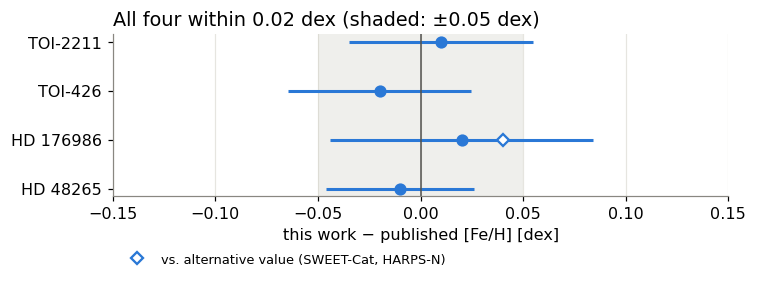

In [4]:
v = val.copy()
v['Δ[Fe/H]'] = v.feh - v.pub_feh
v['Δ/σ'] = v['Δ[Fe/H]'] / np.hypot(v.feh_err, v.pub_feh_err)
v['ΔTeff'] = v.teff - v.pub_teff
v['Δlogg'] = v.logg - v.pub_logg
display(v[['name', 'linelist', 'snr_coadd', 'n_used', 'status', 'feh', 'feh_err', 'pub_feh', 'pub_feh_err',
           'Δ[Fe/H]', 'Δ/σ', 'teff', 'pub_teff', 'ΔTeff', 'logg', 'pub_logg', 'Δlogg', 'pub_ref']]
        .round({'snr_coadd': 0, 'Δ/σ': 2, 'Δlogg': 2}).set_index('name'))

fig, ax = plt.subplots(figsize=(7, 2.9))
yy = np.arange(len(v))[::-1]
ax.errorbar(v['Δ[Fe/H]'], yy, xerr=np.hypot(v.feh_err, v.pub_feh_err), fmt='o', ms=7, color=COL['EBLM'], capsize=0, lw=2)
alt = v.dropna(subset=['alt_feh'])
ax.plot(alt.feh - alt.alt_feh, yy[alt.index], 'D', ms=6, mfc='white', mec=COL['EBLM'], mew=1.5, label='vs. alternative value (SWEET-Cat, HARPS-N)')
ax.axvline(0, color=COL['ink'], lw=1); ax.axvspan(-0.05, 0.05, color=COL['mute'], alpha=0.25, lw=0)
ax.set_yticks(yy, v.name); ax.grid(axis='y', visible=False); ax.set_xlim(-0.15, 0.15)
ax.set_xlabel('this work − published [Fe/H] [dex]'); ax.legend(fontsize=8.5, loc='upper left', bbox_to_anchor=(0, -0.28))
ax.set_title('All four within 0.02 dex (shaded: ±0.05 dex)', loc='left')
plt.tight_layout(); plt.show()

## 3. SWEET-Cat (homogeneous ARES+MOOG)

SWEET-Cat's homogeneous values (`SWFlag = 1`, Sousa et al. 2021) are the largest set measured with exactly this
method, so this is the main test. Two caveats when reading it:

* SWEET-Cat used mostly HARPS (and HARPS-N, ESPRESSO, UVES, FEROS) spectra, often **the same archive spectra** we
  co-added. HARPS agreement therefore tests the pipeline, not independent data; the other instruments, and above all
  SOPHIE (which SWEET-Cat rarely uses), are the real test.
* **Partly circular for the instrument offsets.** Since Nov 15 the `adopt` stage sets each instrument's offset from
  HARPS pairs *and* from SWEET-Cat (free-logg fits of slow rotators, relative to HARPS), so the per-instrument medians
  of the adopted values are pulled towards SWEET-Cat by construction. The HARPS row, the raw columns, the scatter
  and the trends with Teff and rotation are not.

Each panel uses the star's adopted value; the "raw" columns use the same fit before the instrument and fixed-logg
offsets.

237 adopted stars with a homogeneous SWEET-Cat value ({'HJ': 229, 'EBLM': 8}; 276 more in SWEET-Cat but not homogeneous)


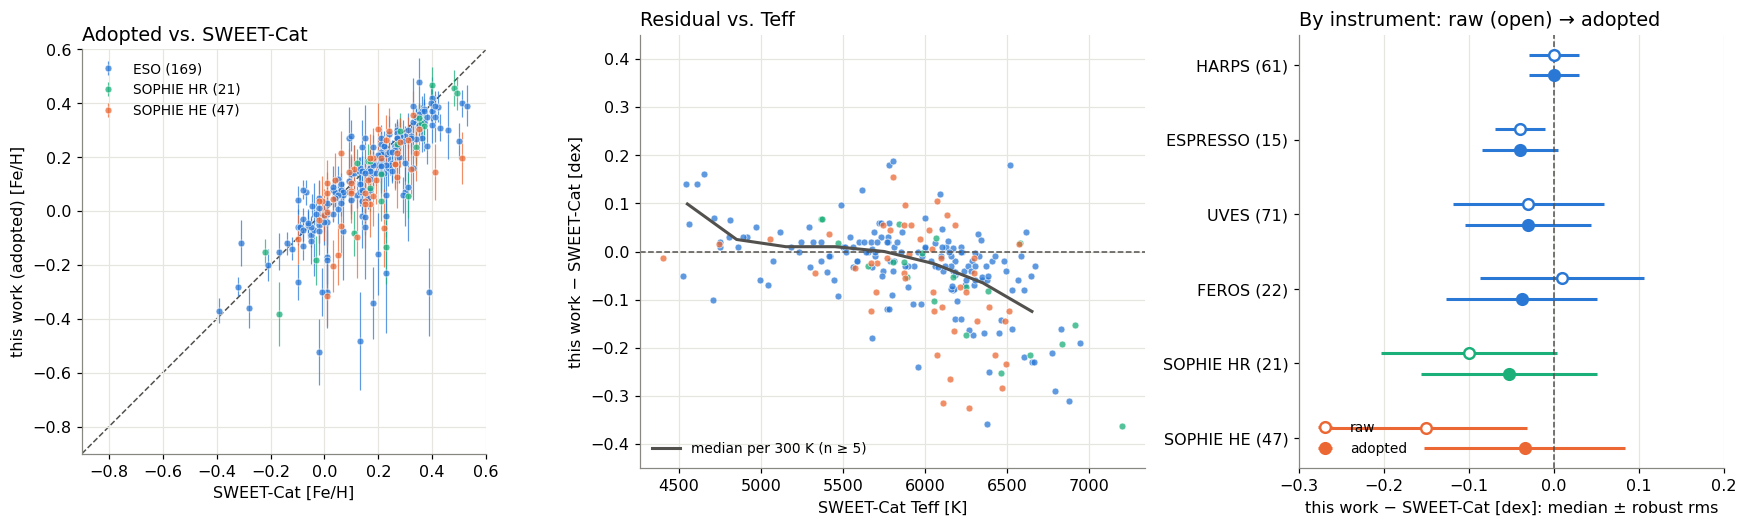

/var/folders/bt/vhrfddss0h90b7tgxvyzlvkr0000gn/T/ipykernel_20132/1207358070.py:41: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  g = d.groupby(by, sort=False)


,n,median Δ raw,median Δ,error,robust rms,robust rms / σ,median ΔTeff [K]
HARPS,61,0.000,0.000,0.005,0.030,0.719,19.0
ESPRESSO,15,-0.040,-0.040,0.014,0.044,0.515,33.0
UVES,71,-0.030,-0.030,0.011,0.074,0.998,78.0
FEROS,22,0.010,-0.038,0.024,0.089,1.473,115.0
SOPHIE HR,21,-0.100,-0.053,0.028,0.104,1.343,37.0
SOPHIE HE,47,-0.150,-0.034,0.022,0.119,1.000,119.0
all,237,-0.033,-0.023,0.006,0.068,0.947,59.0


In [5]:
A = adopt.merge(targets[['target_id'] + list(sc_cols.values())], on='target_id')
H = A[A.sc_homog == 1].copy()
H['d'] = H.feh - H.sc_feh
H['d_raw'] = H.feh_raw - H.sc_feh
H['z'] = H.d / np.hypot(H.feh_err, H.sc_feh_err)
H['dteff'] = H.teff - H.sc_teff
print(f'{len(H)} adopted stars with a homogeneous SWEET-Cat value '
      f"({H['sample'].value_counts().to_dict()}; {len(A) - len(H)} more in SWEET-Cat but not homogeneous)")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.9), gridspec_kw={'width_ratios': [1, 1.25, 1.05]})
ax = axes[0]
for g in GROUPS:
    s = H[H.group == g]
    ax.errorbar(s.sc_feh, s.feh, yerr=s.feh_err, fmt='o', ms=4.5, color=GCOL[g], alpha=0.75, lw=0.8, capsize=0,
                mec='white', mew=0.5, label=f'{g} ({len(s)})')
one_to_one(ax); ax.legend(fontsize=9, loc='upper left')
ax.set(xlabel='SWEET-Cat [Fe/H]', ylabel='this work (adopted) [Fe/H]'); ax.set_title('Adopted vs. SWEET-Cat', loc='left')

ax = axes[1]
for g in GROUPS:
    s = H[H.group == g]
    ax.plot(s.sc_teff, s.d, 'o', ms=4.5, color=GCOL[g], alpha=0.75, mec='white', mew=0.5)
bins = np.arange(4400, 7001, 300)
mid = 0.5 * (bins[1:] + bins[:-1]); b = pd.cut(H.sc_teff, bins)
med = H.groupby(b, observed=False).d.median().values; nb = H.groupby(b, observed=False).d.size().values
ax.plot(mid[nb >= 5], med[nb >= 5], '-', color=COL['ink'], lw=2, label='median per 300 K (n ≥ 5)')
ax.axhline(0, color=COL['ink'], lw=1, ls='--'); ax.set_ylim(-0.45, 0.45)
ax.set(xlabel='SWEET-Cat Teff [K]', ylabel='this work − SWEET-Cat [dex]'); ax.legend(fontsize=9, loc='lower left')
ax.set_title('Residual vs. Teff', loc='left')

ax = axes[2]
yy = np.arange(len(INSTS))[::-1]
for k, inst in enumerate(INSTS):
    s = H[H.inst == inst]
    if s.empty: continue
    for col, dy, mfc, lab in [('d_raw', 0.14, 'white', 'raw'), ('d', -0.14, GCOL[group_of(inst)], 'adopted')]:
        m, e = s[col].median(), robust_std(s[col])
        ax.errorbar(m, yy[k] + dy, xerr=e, fmt='o', ms=7, mfc=mfc, mec=GCOL[group_of(inst)], mew=1.6,
                    color=GCOL[group_of(inst)], lw=2, capsize=0, label=lab if k == len(INSTS) - 1 else None)
ax.axvline(0, color=COL['ink'], lw=1, ls='--')
ax.set_yticks(yy, [f'{i} ({(H.inst == i).sum()})' for i in INSTS]); ax.grid(axis='y', visible=False)
ax.set_xlim(-0.3, 0.2); ax.set_xlabel('this work − SWEET-Cat [dex]: median ± robust rms')
ax.legend(fontsize=9, loc='lower left'); ax.set_title('By instrument: raw (open) → adopted', loc='left')
plt.tight_layout(); plt.show()

tab = summary(H.assign(inst=pd.Categorical(H.inst, INSTS)).sort_values('inst'), 'inst')
tab.insert(1, 'median Δ raw', H.groupby('inst').d_raw.median())
tab['median ΔTeff [K]'] = H.groupby('inst').dteff.median()
tot = summary(H.assign(all='all'), 'all'); tot.insert(1, 'median Δ raw', H.d_raw.median()); tot['median ΔTeff [K]'] = H.dteff.median()
display(pd.concat([tab, tot]).round(3))

In [6]:
# Do the flagged stars agree as well as the clean ones?
FLAGS = ['fixed_logg', 'sophie_he', 'teff_outside_4500_6500', 'vt_ge_2.5', 'snr_lt_50']
rows = [('no flags', H[H.flag_list.map(len) == 0])] + [(f, H[H.flag_list.map(lambda l: f in l)]) for f in FLAGS]
out = pd.concat([summary(s.assign(k=name), 'k') for name, s in rows if len(s)])
display(out.round(3))

# the worst outliers, for inspection (|Δ| > 3 robust rms)
lim = 3 * robust_std(H.d)
print(f'outliers, |Δ| > {lim:.2f} dex:')
display(H.loc[H.d.abs() > lim, ['name', 'sample', 'mode', 'method', 'feh', 'feh_err', 'sc_feh', 'd', 'teff', 'sc_teff',
                                 'logg', 'sc_logg', 'vt', 'snr_coadd', 'flags', 'sc_ref']]
        .sort_values('d').round(3).reset_index(drop=True))

,n,median Δ,error,robust rms,robust rms / σ
k,,,,,
no flags,127,-0.010,0.005,0.044,0.764
fixed_logg,38,-0.061,0.025,0.123,1.065
sophie_he,47,-0.034,0.022,0.119,1.000
teff_outside_4500_6500,46,-0.099,0.025,0.138,1.013
vt_ge_2.5,26,-0.134,0.025,0.101,0.845
snr_lt_50,13,-0.030,0.016,0.045,0.478


outliers, |Δ| > 0.20 dex:


,name,sample,mode,method,feh,feh_err,sc_feh,d,teff,sc_teff,logg,sc_logg,vt,snr_coadd,flags,sc_ref
0,TOI-163,HJ,UVES_R107000,free,-0.300,0.163,0.387,-0.687,6404.0,6761.0,4.25,4.882,1.52,126.195,vbroad_ge_10,Sousa et al. 2024
1,HAT-P-41,HJ,FEROS_R48000,free,-0.483,0.182,0.130,-0.613,6862.0,6479.0,4.96,4.390,1.59,142.288,teff_outside_4500_6500;vbroad_ge_10,Tsantaki et al. 2014
2,WASP-136,HJ,UVES_R107000,free,-0.340,0.133,0.180,-0.520,6144.0,6770.0,3.89,4.570,0.92,219.167,vbroad_ge_10,Sousa et al. 2021
3,WASP-66,HJ,FEROS_R48000,free,-0.523,0.124,-0.020,-0.503,6544.0,6756.0,4.22,4.430,1.63,93.589,teff_outside_4500_6500;vbroad_ge_10,Sousa et al. 2021
4,WASP-187,HJ,UVES_R107000,free,-0.230,0.222,0.228,-0.458,6424.0,6346.0,4.61,4.040,1.41,83.152,vbroad_ge_10,Sousa et al. 2024
5,HAT-P-49,HJ,SOPHIE_HR_R75000,free,-0.133,0.138,0.230,-0.363,7088.0,7201.0,4.21,4.710,2.01,182.309,teff_outside_4500_6500;vbroad_ge_10,Sousa et al. 2021
6,TOI-2236,HJ,UVES_R107000,free,-0.160,0.153,0.198,-0.358,6112.0,6378.0,3.97,4.424,1.42,59.834,vbroad_ge_10,Sousa et al. 2024
7,CoRoT-6,HJ,SOPHIE_HE_R39000,fixlogg,-0.314,0.114,0.010,-0.324,6403.0,6265.0,4.44,4.600,1.87,93.777,fixed_logg;sophie_he,Sousa et al. 2021
8,WASP-114,HJ,SOPHIE_HE_R39000,free,0.196,0.096,0.510,-0.314,6169.0,6110.0,4.80,4.440,1.80,95.815,sophie_he,Sousa et al. 2021
9,WASP-100,HJ,UVES_R107000,free,-0.300,0.133,0.010,-0.310,6823.0,6877.0,4.28,4.420,1.80,69.529,teff_outside_4500_6500;vbroad_ge_10,Sousa et al. 2021


### The hot-star offset

Agreement with SWEET-Cat is excellent below ~6000 K and degrades with Teff on every instrument, reaching about
−0.2 dex above 6600 K. Is it inherited from a different logg, Teff or microturbulence ξ (a parameter that differs
from SWEET-Cat's pulls [Fe/H] with it), or is it line broadening? Hot stars rotate faster (above the Kraft break,
~6300 K), and ARES fits Gaussians to blended, rotationally broadened lines poorly. The last panel uses `vbroad`
(rotation + macroturbulence) from the PHOENIX fit of the same stars.

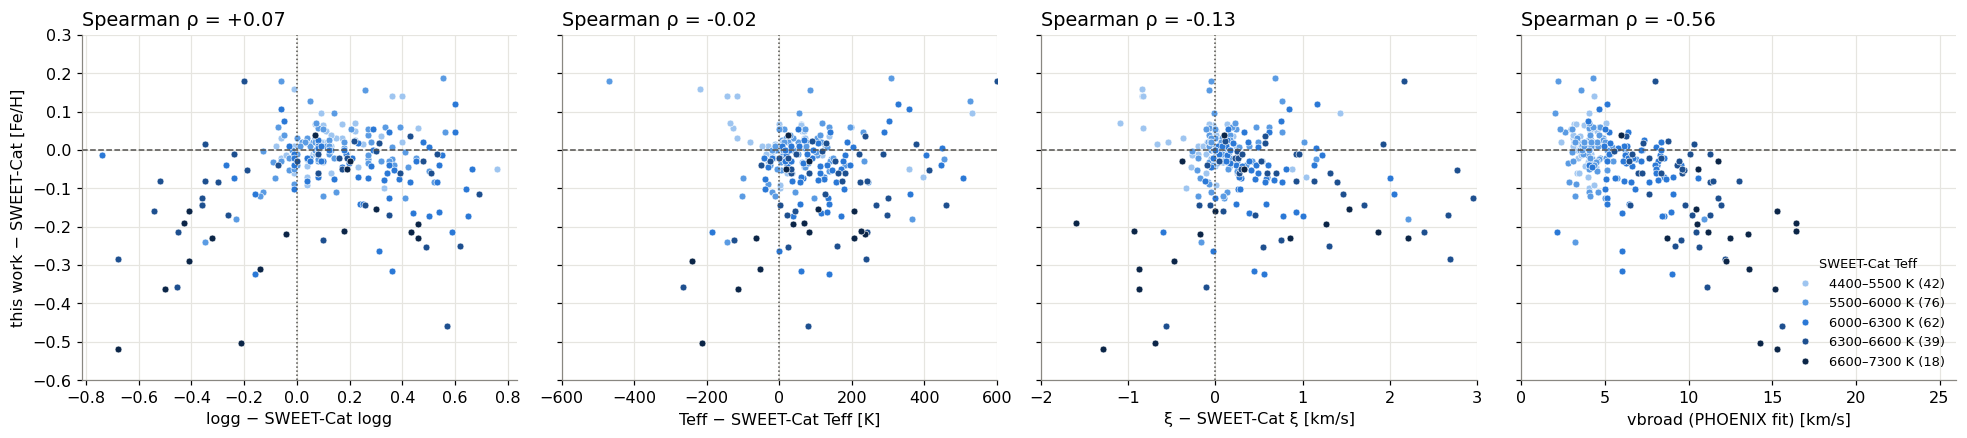

robust fit: Δ[Fe/H] = -0.020 -0.037 × Δξ  (±0.007)


,n,median Δ[Fe/H],after removing ξ term,median Δlogg,median ΔTeff,median ξ (ours),median ξ (SWEET-Cat),median vbroad
tbin,,,,,,,,
"(4400, 5500]",42,0.019,0.016,0.105,14.0,0.795,0.860,3.743
"(5500, 6000]",76,0.000,0.000,0.080,30.0,1.100,1.055,4.176
"(6000, 6300]",62,-0.040,-0.026,0.235,106.0,1.635,1.320,6.512
"(6300, 6600]",38,-0.060,-0.038,0.080,142.0,2.305,1.600,9.601
"(6600, 7300]",18,-0.217,-0.212,-0.090,31.0,1.820,2.022,13.015


,n,median Δ[Fe/H],robust rms,median Teff
vbroad [km/s],,,,
"(0, 8]",163,0.000,0.044,5801.0
"(8, 10]",35,-0.053,0.038,6277.0
"(10, 15]",26,-0.170,0.131,6551.5
"(15, 40]",8,-0.410,0.298,6772.0


slow rotators only (vbroad < 8 km/s):


,n,median Δ[Fe/H],robust rms
tbin,,,
"(4400, 5500]",39,0.017,0.047
"(5500, 6000]",73,0.000,0.044
"(6000, 6300]",40,-0.030,0.068
"(6300, 6600]",10,-0.025,0.052
"(6600, 7300]",1,0.040,0.000


In [7]:
H['dlogg'] = H.logg - H.sc_logg
H['dvt'] = H.vt - H.sc_vt
TB = [4400, 5500, 6000, 6300, 6600, 7300]
H['tbin'] = pd.cut(H.sc_teff, TB)
tcol = dict(zip(H.tbin.cat.categories, ['#9ec5f0', '#5a9be3', COL['EBLM'], '#1d4f8f', '#0b2547']))   # light -> dark = cool -> hot
fig, axes = plt.subplots(1, 4, figsize=(18, 4.1), sharey=True)
for ax, col, lab in zip(axes, ['dlogg', 'dteff', 'dvt', 'vbroad'], ['logg − SWEET-Cat logg', 'Teff − SWEET-Cat Teff [K]',
                                                                  'ξ − SWEET-Cat ξ [km/s]', 'vbroad (PHOENIX fit) [km/s]']):
    for b in H.tbin.cat.categories:
        s = H[H.tbin == b]
        ax.plot(s[col], s.d, 'o', ms=4.5, color=tcol[b], mec='white', mew=0.4, label=f'{b.left:.0f}–{b.right:.0f} K ({len(s)})')
    r = stats.spearmanr(H[col], H.d, nan_policy='omit')
    ax.axhline(0, color=COL['ink'], lw=1, ls='--'); ax.axvline(0, color=COL['ink'], lw=1, ls=':')
    ax.set_xlabel(lab); ax.set_title(f'Spearman ρ = {r.statistic:+.2f}', loc='left')
axes[0].set_ylabel('this work − SWEET-Cat [Fe/H]'); axes[0].set_ylim(-0.6, 0.3)
axes[1].set_xlim(-600, 600); axes[2].set_xlim(-2, 3); axes[3].set_xlim(0, 26)
axes[3].legend(fontsize=8.5, title='SWEET-Cat Teff', title_fontsize=8.5, loc='lower right')
plt.tight_layout(); plt.show()

# remove the part of the residual that follows ξ, and see what is left in each Teff bin
import statsmodels.api as sm
ok = H.dropna(subset=['dvt'])
fit = sm.RLM(ok.d, sm.add_constant(ok[['dvt']])).fit()
ok = ok.assign(d_vt_removed=ok.d - fit.params['dvt'] * ok.dvt)
print(f"robust fit: Δ[Fe/H] = {fit.params['const']:+.3f} {fit.params['dvt']:+.3f} × Δξ  (±{fit.bse['dvt']:.3f})")
display(ok.groupby('tbin', observed=True).agg(n=('d', 'size'), **{'median Δ[Fe/H]': ('d', 'median'),
        'after removing ξ term': ('d_vt_removed', 'median'), 'median Δlogg': ('dlogg', 'median'),
        'median ΔTeff': ('dteff', 'median'), 'median ξ (ours)': ('vt', 'median'), 'median ξ (SWEET-Cat)': ('sc_vt', 'median'),
        'median vbroad': ('vbroad', 'median')}).round(3))

# the same residual split by broadening, and by Teff within the slow rotators
VB = [0, 8, 10, 15, 40]
display(H.groupby(pd.cut(H.vbroad, VB), observed=True).agg(n=('d', 'size'), **{'median Δ[Fe/H]': ('d', 'median'),
        'robust rms': ('d', robust_std), 'median Teff': ('sc_teff', 'median')}).rename_axis('vbroad [km/s]').round(3))
slow = H[H.vbroad < 8]
print('slow rotators only (vbroad < 8 km/s):')
display(slow.groupby('tbin', observed=True).agg(n=('d', 'size'), **{'median Δ[Fe/H]': ('d', 'median'),
        'robust rms': ('d', robust_std)}).round(3))

**Result: the offset is line broadening, not Teff.** Among slow rotators (vbroad < 8 km/s) the adopted values match
SWEET-Cat at every Teff (−0.03 dex at most, even at 6300–6600 K; robust rms 0.04–0.07 dex). The residual grows with
broadening: −0.05 dex at 8–10 km/s, −0.17 dex at 10–15 km/s and −0.41 dex above 15 km/s. It only looks like a Teff
trend because hotter stars rotate faster. Neither logg nor Teff differences explain it (ρ ≈ 0); ξ accounts for a
small part (−0.04 dex per km/s of ξ difference) between 6000 and 6600 K.

We cannot tell from this comparison alone which side is wrong for fast rotators, but our EWs of broadened lines are
the more likely culprit: ARES fits Gaussians and needs a tuned continuum (`rejt`) and blending treatment for broad
lines. Until that is checked, the `adopt` stage **flags vbroad ≥ 10 km/s as `vbroad_ge_10`** (97 of 513 stars;
vbroad from the PHOENIX fits) and leaves those stars out when it measures instrument offsets against SWEET-Cat.

## 4. EBLM primaries with published ARES+MOOG [Fe/H]

EBLM VIII (Swayne et al. 2021), IX (Sebastian et al. 2023) and XI (Swayne et al. 2024) measured their primaries with
ARES+MOOG, on CORALIE, HARPS, SOPHIE and FIES spectra. Repeat entries for the same star (EBLM XI re-lists earlier
values) are averaged. The M-dwarf companion contributes < 1% of the optical light, so it does not bias the EWs
noticeably.

17 EBLMs with ARES+MOOG literature [Fe/H]; 11 have an adopted value here
not in our sample: J0113+31 (FIES), J0123+38 (FIES), J0540-17 (CORALIE), J0941-31 (HARPS), J2046-40 (CORALIE), J2359+44 (SOPHIE)


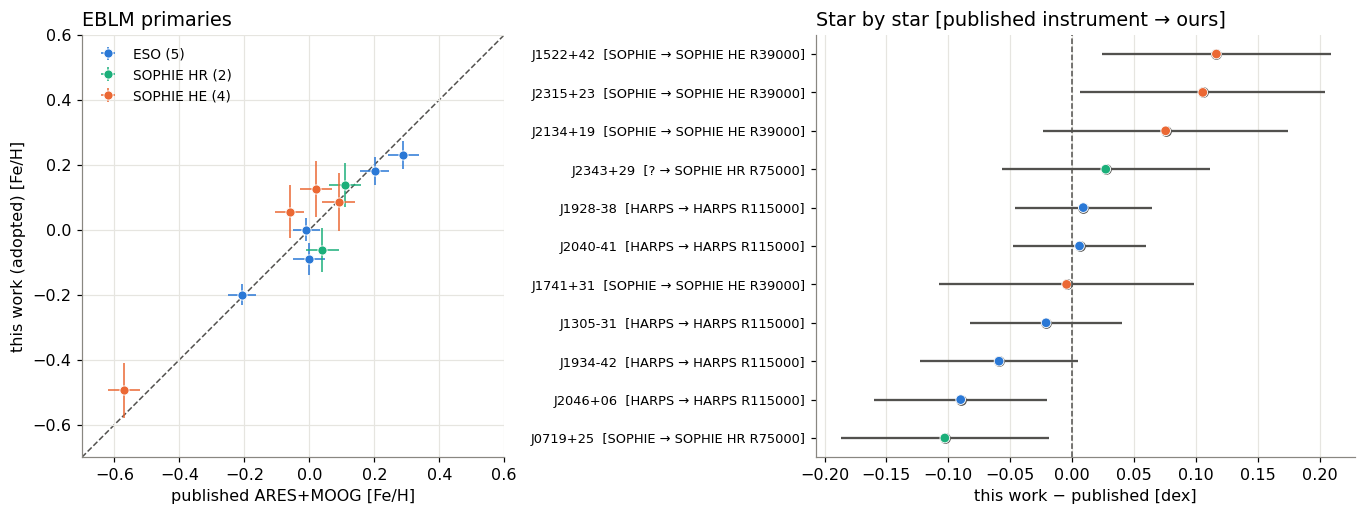

,n,median Δ,error,robust rms,robust rms / σ
k,,,,,
EBLM ARES+MOOG literature,11,0.006,0.036,0.096,0.967


In [8]:
lit = pd.read_csv(f'{D}/eblm_literature_feh.csv')
lit = lit[lit.method.str.startswith('ARES')]
short = targets[targets['sample'] == 'EBLM'].assign(s=lambda d: d.name.str.replace('EBLM ', '')).drop_duplicates('s').set_index('s').target_id
lit = (lit.assign(target_id=lit.name.map(short))
       .groupby('name').agg(target_id=('target_id', 'first'), lit_feh=('feh', 'mean'), lit_err=('feh_err', 'mean'),
                            lit_teff=('teff', 'mean'), lit_inst=('instrument', 'first'), ref=('reference', 'last')))
E = lit.reset_index().merge(adopt, on='target_id', how='left')
miss = E[E.feh.isna()]
E = E.dropna(subset=['feh'])
E['d'] = E.feh - E.lit_feh
E['z'] = E.d / np.hypot(E.feh_err, E.lit_err)
print(f'{len(lit)} EBLMs with ARES+MOOG literature [Fe/H]; {len(E)} have an adopted value here')
print('not in our sample:', ', '.join(f'{n} ({i})' for n, i in zip(miss.name_x if 'name_x' in miss else miss.name, miss.lit_inst)) or 'none')

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12.5, 4.8), gridspec_kw={'width_ratios': [1, 1.2]})
for g in GROUPS:
    s = E[E.group == g]
    a1.errorbar(s.lit_feh, s.feh, xerr=s.lit_err, yerr=s.feh_err, fmt='o', ms=6, color=GCOL[g], lw=1, capsize=0,
                mec='white', mew=0.6, label=f'{g} ({len(s)})')
one_to_one(a1, -0.7, 0.6); a1.legend(fontsize=9, loc='upper left')
a1.set(xlabel='published ARES+MOOG [Fe/H]', ylabel='this work (adopted) [Fe/H]'); a1.set_title('EBLM primaries', loc='left')
E = E.sort_values('d')
yy = np.arange(len(E))
a2.errorbar(E.d, yy, xerr=np.hypot(E.feh_err, E.lit_err), fmt='o', ms=6, lw=1.5, capsize=0, color=COL['ink'], zorder=1)
a2.scatter(E.d, yy, s=40, c=[GCOL[g] for g in E.group], zorder=2, edgecolors='white', linewidths=0.6)
a2.set_yticks(yy, [f"{n}  [{i} → {m.replace('_', ' ')}]" for n, i, m in
                   zip(E.name_x if 'name_x' in E else E.name, E.lit_inst.fillna('?'), E['mode'])], fontsize=8.5)
a2.axvline(0, color=COL['ink'], lw=1, ls='--'); a2.grid(axis='y', visible=False)
a2.set_xlabel('this work − published [dex]'); a2.set_title('Star by star [published instrument → ours]', loc='left')
plt.tight_layout(); plt.show()
display(summary(E.assign(k='EBLM ARES+MOOG literature'), 'k').round(3))

## 5. SOPHIE

`hpc/ares_moog/sophie_test.py` traced the SOPHIE HE problem to the spectra, not the method: equivalent widths come out
~12% low (an additive pedestal plus a continuum placed too low), not because of the lower resolution. The `adopt`
stage therefore subtracts a [Fe/H] offset per instrument. It measures the offset two ways, from free-logg fits:
(a) stars that also have a HARPS fit, and (b) SWEET-Cat's homogeneous values for slow rotators (vbroad < 10 km/s),
relative to HARPS's own offset from SWEET-Cat. It applies their inverse-variance mean when it is significant
(`results/feh_offsets.csv` keeps both estimates). The checks below:

* **left:** the offset applied by `adopt` next to two checks made here from each star's *adopted* fit (one per star,
  including fixed-logg fits): against SWEET-Cat directly, and Teff-matched to the ESO stars.
* **middle:** does the SOPHIE HE offset depend on S/N or Teff? A constant offset would not fix a trend.
* **right:** the stars with both a SOPHIE and a HARPS fit, raw.

median SWEET-Cat Teff of the comparison stars: {'HARPS': 5803.0, 'ESPRESSO': 6103.0, 'UVES': 5955.0, 'FEROS': 6164.0, 'SOPHIE HR': 6063.0, 'SOPHIE HE': 6049.0}
SOPHIE HR: Spearman ρ(raw Δ, log S/N) = -0.01 (p = 0.96); ρ(raw Δ, Teff) = -0.79 (p = 0.00)
SOPHIE HE: Spearman ρ(raw Δ, log S/N) = +0.34 (p = 0.02); ρ(raw Δ, Teff) = -0.30 (p = 0.04)


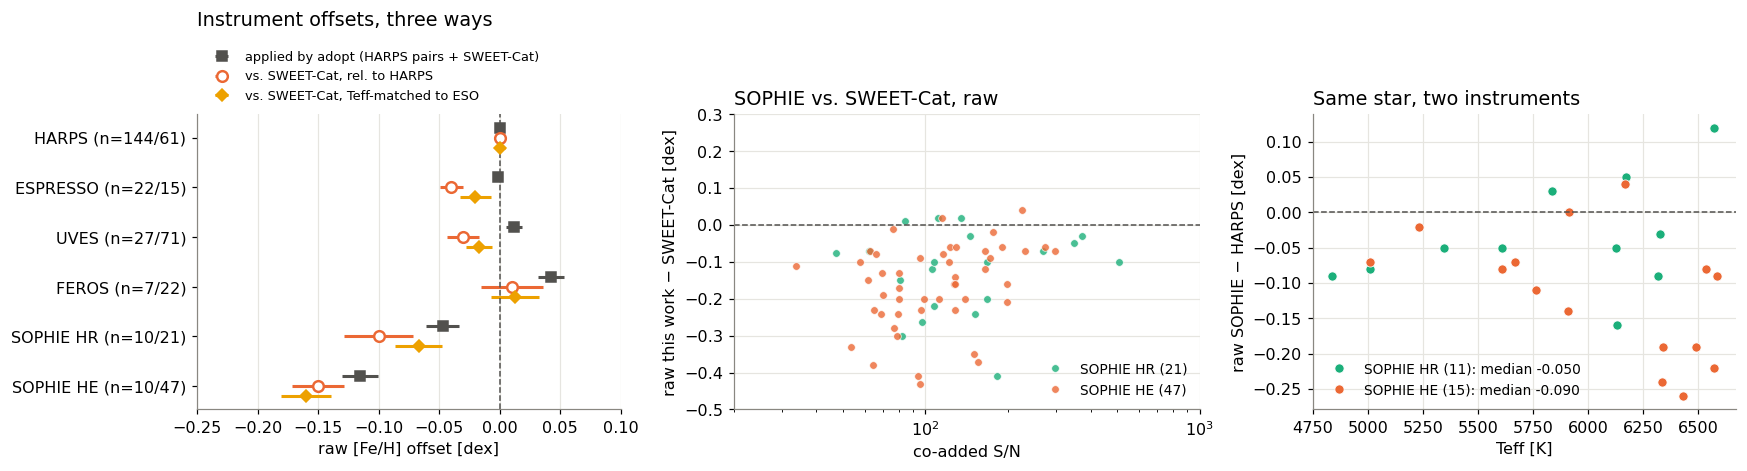

,n,offset,offset_err,applied,sc,n_sc,sc_err,sc − HARPS,sc_tm,sc_tm_err,sc_tm − HARPS,slow: sc − HARPS,n slow
inst,,,,,,,,,,,,,
HARPS,144,0.000,0.000,False,0.00,61,0.005,0.00,0.007,0.004,0.000,0.000,55
ESPRESSO,22,-0.002,0.004,False,-0.04,15,0.010,-0.04,-0.013,0.013,-0.020,-0.033,11
UVES,27,0.012,0.007,False,-0.03,71,0.013,-0.03,-0.010,0.011,-0.017,-0.010,57
FEROS,7,0.043,0.011,True,0.01,22,0.026,0.01,0.020,0.020,0.013,0.020,17
SOPHIE HR,10,-0.047,0.014,True,-0.10,21,0.028,-0.10,-0.060,0.020,-0.067,-0.070,15
SOPHIE HE,10,-0.116,0.015,True,-0.15,47,0.022,-0.15,-0.153,0.021,-0.160,-0.140,43


In [9]:
o = offsets[offsets.kind == 'instrument'].copy()
o['inst'] = o.inst.map(inst_of)
o = o.groupby('inst').first()        # UVES modes share one pooled offset
sc_off = H.groupby('inst').d_raw.agg(['median', 'size', lambda x: 1.2533 * robust_std(x) / np.sqrt(len(x))])
sc_off.columns = ['sc', 'n_sc', 'sc_err']
# the HARPS raw offset vs SWEET-Cat is the zero point of the comparison: SWEET-Cat − HARPS sets the scale
cmp_ = o[['n', 'offset', 'offset_err', 'applied']].join(sc_off).reindex(INSTS)
cmp_['sc − HARPS'] = cmp_.sc - cmp_.loc['HARPS', 'sc']
# SOPHIE's SWEET-Cat stars are hotter than the ESO ones, so part of their offset is the hot-star trend above.
# Teff-matched: subtract from each star the median raw residual of ESO stars within ±200 K of its Teff.
eso = H[H.group == 'ESO']
def eso_trend(t, w=200):
    s = eso[(eso.sc_teff - t).abs() < w]
    return s.d_raw.median() if len(s) >= 5 else np.nan
H['d_raw_tm'] = H.d_raw - H.sc_teff.map(eso_trend)
tm = H.groupby('inst').d_raw_tm.agg(['median', lambda x: 1.2533 * robust_std(x) / np.sqrt(x.notna().sum())])
tm.columns = ['sc_tm', 'sc_tm_err']
cmp_ = cmp_.join(tm)
cmp_['sc_tm − HARPS'] = cmp_.sc_tm - cmp_.loc['HARPS', 'sc_tm']
# and among slow rotators only (vbroad < 10 km/s), where the broadening bias is absent
sl = H[H.vbroad < 10].groupby('inst').d_raw.agg(['median', 'size'])
cmp_['slow: sc − HARPS'] = sl['median'] - sl.loc['HARPS', 'median']
cmp_['n slow'] = sl['size']
print('median SWEET-Cat Teff of the comparison stars:', H.groupby('inst').sc_teff.median().reindex(INSTS).round(0).to_dict())

fig, axes = plt.subplots(1, 3, figsize=(16, 4.4), gridspec_kw={'width_ratios': [1, 1.1, 1]})
ax = axes[0]
yy = np.arange(len(INSTS))[::-1]
ax.errorbar(cmp_.offset, yy + 0.2, xerr=cmp_.offset_err, fmt='s', ms=7, color=COL['ink'], lw=2, capsize=0, label='applied by adopt (HARPS pairs + SWEET-Cat)')
ax.errorbar(cmp_['sc − HARPS'], yy, xerr=cmp_.sc_err, fmt='o', ms=7, mfc='white', color=COL['HJ'], mew=1.6, lw=2,
            capsize=0, label='vs. SWEET-Cat, rel. to HARPS')
ax.errorbar(cmp_['sc_tm − HARPS'], yy - 0.2, xerr=cmp_.sc_tm_err, fmt='D', ms=6, color=COL['alt2'], lw=2,
            capsize=0, label='vs. SWEET-Cat, Teff-matched to ESO')
ax.axvline(0, color=COL['ink'], lw=1, ls='--')
ax.set_yticks(yy, [f'{i} (n={int(n) if n == n else 0}/{int(m) if m == m else 0})' for i, n, m in zip(INSTS, cmp_.n, cmp_.n_sc)])
ax.grid(axis='y', visible=False); ax.set_xlabel('raw [Fe/H] offset [dex]')
ax.legend(fontsize=8.5, loc='lower left', bbox_to_anchor=(0, 1.0)); ax.set_xlim(-0.25, 0.1)
ax.set_title('Instrument offsets, three ways', loc='left', pad=58)

he = H[H.inst == 'SOPHIE HE']; hr = H[H.inst == 'SOPHIE HR']
ax = axes[1]
for s, g in [(hr, 'SOPHIE HR'), (he, 'SOPHIE HE')]:
    ax.plot(s.snr_coadd, s.d_raw, 'o', ms=5, color=GCOL[g], alpha=0.8, mec='white', mew=0.5, label=f'{g} ({len(s)})')
    r = stats.spearmanr(np.log(s.snr_coadd), s.d_raw)
    print(f'{g}: Spearman ρ(raw Δ, log S/N) = {r.statistic:+.2f} (p = {r.pvalue:.2f}); '
          f'ρ(raw Δ, Teff) = {stats.spearmanr(s.teff, s.d_raw).statistic:+.2f} (p = {stats.spearmanr(s.teff, s.d_raw).pvalue:.2f})')
ax.set_xscale('log'); ax.set_xlim(20, 1000); ax.axhline(0, color=COL['ink'], lw=1, ls='--'); ax.set_ylim(-0.5, 0.3)
ax.set(xlabel='co-added S/N', ylabel='raw this work − SWEET-Cat [dex]'); ax.legend(fontsize=9, loc='lower right')
ax.set_title('SOPHIE vs. SWEET-Cat, raw', loc='left')

ax = axes[2]
p = cand.pivot_table(index='target_id', columns='inst', values='feh_raw', aggfunc='first')
tf = cand.groupby('target_id').teff.median()
for g in ['SOPHIE HR', 'SOPHIE HE']:
    if g in p and 'HARPS' in p:
        s = p[['HARPS', g]].dropna()
        ax.plot(tf[s.index], s[g] - s.HARPS, 'o', ms=6, color=GCOL[g], mec='white', mew=0.5,
                label=f'{g} ({len(s)}): median {np.median(s[g] - s.HARPS):+.3f}')
ax.axhline(0, color=COL['ink'], lw=1, ls='--')
ax.set(xlabel='Teff [K]', ylabel='raw SOPHIE − HARPS [dex]'); ax.legend(fontsize=9, loc='lower left')
ax.set_title('Same star, two instruments', loc='left')
plt.tight_layout(); plt.show()
display(cmp_.round(3))

**Result.** The first `adopt` run used only the HARPS pairs and applied −0.095 ± 0.035 dex to SOPHIE HE from just
10 stars; their difference grows with Teff and rotation (right panel), so it depended on which stars happen to
overlap. With SWEET-Cat added (−0.120 ± 0.016 from 51 slow-rotator fits), the applied offset is now
**−0.116 ± 0.015 dex**, and SOPHIE HE stars agree with SWEET-Cat to −0.034 ± 0.022 dex (was −0.055). SOPHIE HR:
−0.047 applied (pairs −0.050, SWEET-Cat −0.045), consistent with the checks here.

The checks in this notebook still read SOPHIE HE ≈ −0.15 relative to HARPS because they use each star's adopted fit,
i.e. only the stars with no better spectrum, which are fainter. Their raw offset is −0.155 against −0.115 for all
SOPHIE HE fits of slow rotators, and the residual rises with S/N (middle panel, ρ = +0.34, p = 0.02), as an additive
pedestal would. The remaining −0.04 ± 0.02 for those stars is < 2σ; an S/N-dependent SOPHIE HE correction would be
the next refinement. The SOPHIE HE scatter (robust rms 0.12 dex, normalised rms ≈ 1) is consistent with its errors.

Among the ESO instruments the two estimates agree, so UVES R107000 is no longer corrected (+0.012 ± 0.007) and FEROS
keeps +0.043. UVES R57000 is the exception: pairs +0.02, SWEET-Cat −0.07 (3.5σ apart; `adopt` prints a note).

## 6. Results: hot-Jupiter hosts vs. EBLM primaries

Same comparison as `Metallicity_Survey.ipynb` (Teff 5300–7000 K), now with the ARES+MOOG values. The middle panel
repeats it without the stars whose value is less secure (SOPHIE HE, fixed logg, ξ ≥ 2.5 km/s), and the right panel
keeps only slow rotators (vbroad < 10 km/s), where ARES+MOOG matches SWEET-Cat at every Teff (section 3). EBLM
primaries rotate a little faster than hot-Jupiter hosts (tidal spin-up), so the rotation bias could in principle mimic
a lower EBLM metallicity. CORALIE spectra are not in the ARES+MOOG run yet, so ~100 EBLMs that the PHOENIX survey had are
missing here.

median vbroad [km/s]: {'EBLM': 7.4, 'HJ': 5.7}


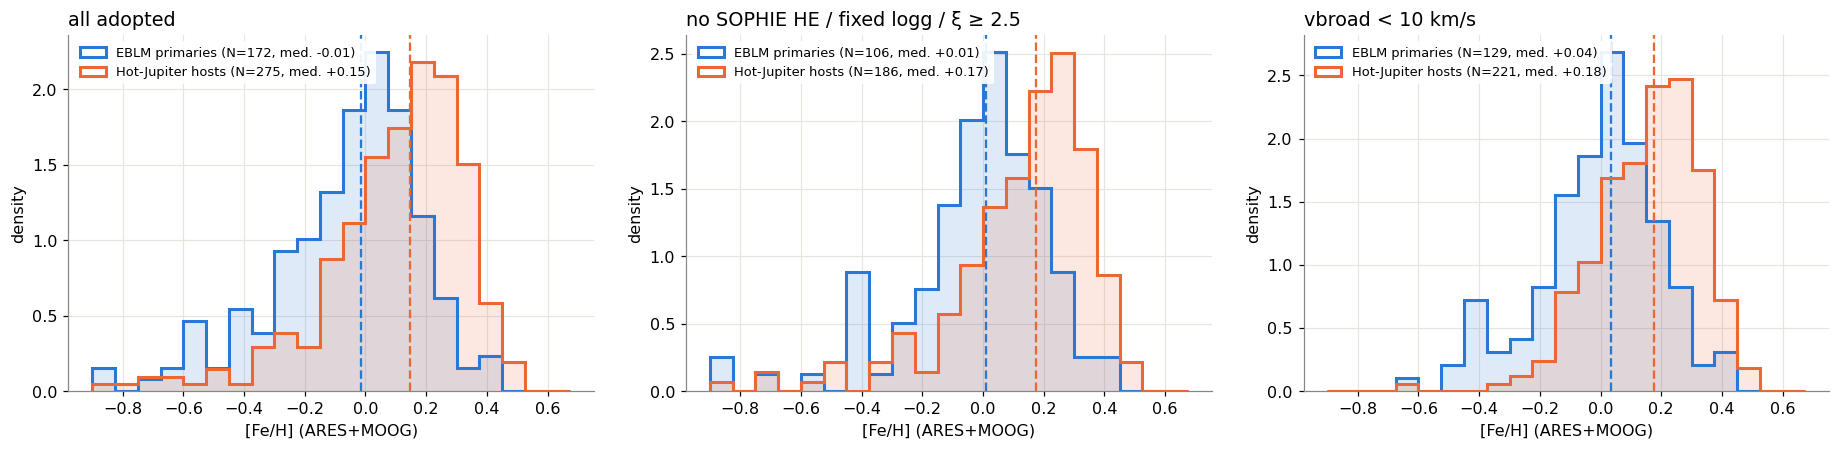

,N HJ,N EBLM,median HJ,median EBLM,HJ − EBLM,error (boot),σ,KS p,Mann–Whitney p
all adopted,275.000000,172.000000,+0.146,-0.014,+0.159,0.024,6.5,3.4e-11,6.6e-14
no SOPHIE HE / fixed logg / ξ ≥ 2.5,186.000000,106.000000,+0.174,+0.010,+0.164,0.028,5.8,2.6e-08,8.9e-10
vbroad < 10 km/s,221.000000,129.000000,+0.176,+0.036,+0.140,0.026,5.5,1.8e-10,5.5e-14


In [10]:
def compare(a, b, n_boot=10000, seed=2):
    a, b = np.asarray(a, float), np.asarray(b, float)
    rng = np.random.default_rng(seed)
    boot = [np.median(rng.choice(a, a.size)) - np.median(rng.choice(b, b.size)) for _ in range(n_boot)]
    d = np.median(a) - np.median(b)
    return {'N HJ': a.size, 'N EBLM': b.size, 'median HJ': np.median(a), 'median EBLM': np.median(b),
            'HJ − EBLM': d, 'error (boot)': np.std(boot), 'σ': d / np.std(boot),
            'KS p': stats.ks_2samp(a, b).pvalue, 'Mann–Whitney p': stats.mannwhitneyu(a, b).pvalue}

S = adopt[adopt.teff.between(*TEFF)]
print('median vbroad [km/s]:', S.groupby('sample').vbroad.median().round(1).to_dict())
risky = S.flag_list.map(lambda l: bool({'sophie_he', 'fixed_logg', 'vt_ge_2.5'} & set(l)))
sets = {'all adopted': S, 'no SOPHIE HE / fixed logg / ξ ≥ 2.5': S[~risky], 'vbroad < 10 km/s': S[S.vbroad < 10]}
bins = np.arange(-0.9, 0.75, 0.075)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2), sharex=True)
rows = {}
for ax, (lab, s) in zip(axes, sets.items()):
    hj, eb = s[s['sample'] == 'HJ'].feh, s[s['sample'] == 'EBLM'].feh
    rows[lab] = compare(hj, eb)
    for x, k in [(eb, 'EBLM'), (hj, 'HJ')]:
        ax.hist(x, bins, density=True, histtype='stepfilled', color=COL[k], alpha=0.15)
        ax.hist(x, bins, density=True, histtype='step', color=COL[k], lw=2,
                label=f'{SAMPLE_LABEL[k]} (N={len(x)}, med. {np.median(x):+.2f})')
        ax.axvline(np.median(x), color=COL[k], lw=1.5, ls='--')
    ax.set(xlabel='[Fe/H] (ARES+MOOG)', ylabel='density'); ax.legend(fontsize=8.5, loc='upper left', frameon=True, framealpha=0.92, edgecolor='none')
    ax.set_title(lab, loc='left')
plt.tight_layout(); plt.show()
display(pd.DataFrame(rows).T.style.format({'median HJ': '{:+.3f}', 'median EBLM': '{:+.3f}', 'HJ − EBLM': '{:+.3f}',
                                            'error (boot)': '{:.3f}', 'σ': '{:.1f}', 'KS p': '{:.1e}', 'Mann–Whitney p': '{:.1e}'}))

**Result.** With ARES+MOOG, hot-Jupiter hosts are more metal-rich than EBLM primaries by **+0.16 ± 0.02 dex
(6.5σ)**: medians +0.15 and −0.01 for 275 hosts and 172 EBLMs. It does not depend on the less secure stars
(+0.16 ± 0.03 without SOPHIE HE / fixed-logg / high-ξ fits) or on rotation (+0.14 ± 0.03 for vbroad < 10 km/s). This agrees with the PHOENIX-fit result in `Metallicity_Survey.ipynb`
(+0.16 ± 0.01 dex, with ~100 more CORALIE EBLMs), now with a method that is directly comparable to the literature.

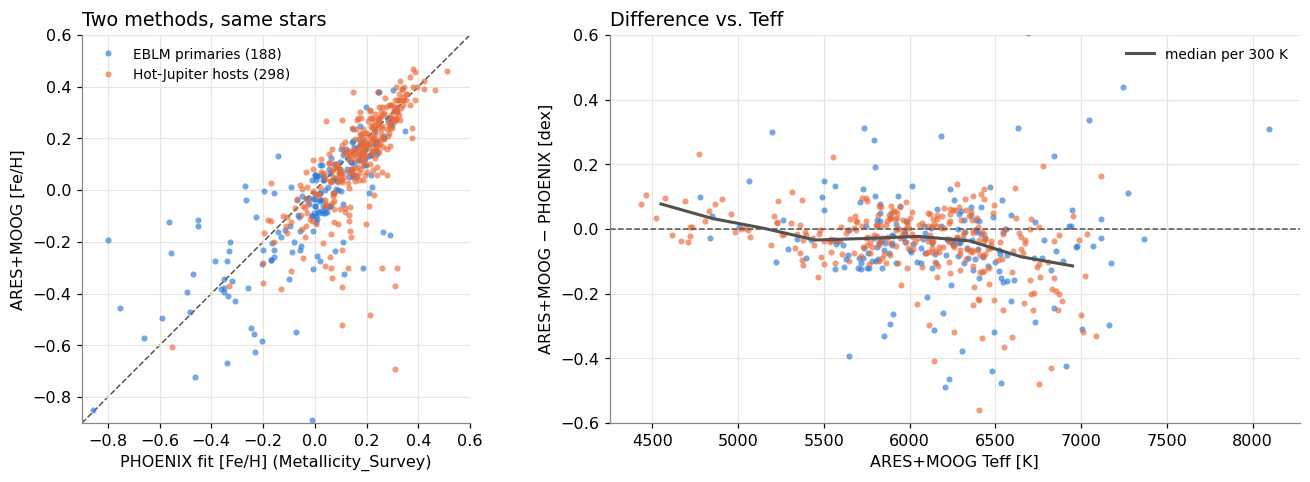

,n,median Δ,error,robust rms
k,,,,
Hot-Jupiter hosts,298,-0.028,0.005,0.075
EBLM primaries,188,-0.042,0.008,0.090


In [11]:
# ARES+MOOG vs the PHOENIX fit (whose zero point was itself tied to SWEET-Cat/ARES+MOOG calibrators)
P = adopt.merge(phoenix[['target_id', 'feh', 'feh_err', 'teff']].rename(columns={'feh': 'ph_feh', 'feh_err': 'ph_err', 'teff': 'ph_teff'}),
                on='target_id')
P['d'] = P.feh - P.ph_feh
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12.5, 4.5), gridspec_kw={'width_ratios': [1, 1.3]})
for k in ['EBLM', 'HJ']:
    s = P[P['sample'] == k]
    a1.plot(s.ph_feh, s.feh, 'o', ms=4, alpha=0.65, color=COL[k], mec='none', label=f'{SAMPLE_LABEL[k]} ({len(s)})')
    a2.plot(s.teff, s.d, 'o', ms=4, alpha=0.65, color=COL[k], mec='none')
one_to_one(a1); a1.legend(fontsize=9, loc='upper left')
a1.set(xlabel='PHOENIX fit [Fe/H] (Metallicity_Survey)', ylabel='ARES+MOOG [Fe/H]'); a1.set_title('Two methods, same stars', loc='left')
bins = np.arange(4400, 7101, 300); mid = 0.5 * (bins[1:] + bins[:-1]); b = pd.cut(P.teff, bins)
med = P.groupby(b, observed=False).d.median().values; nb = P.groupby(b, observed=False).d.size().values
a2.plot(mid[nb >= 5], med[nb >= 5], '-', color=COL['ink'], lw=2, label='median per 300 K')
a2.axhline(0, color=COL['ink'], lw=1, ls='--'); a2.set_ylim(-0.6, 0.6); a2.legend(fontsize=9)
a2.set(xlabel='ARES+MOOG Teff [K]', ylabel='ARES+MOOG − PHOENIX [dex]'); a2.set_title('Difference vs. Teff', loc='left')
plt.tight_layout(); plt.show()
display(summary(P.assign(k=P['sample'].map(SAMPLE_LABEL)), 'k').round(3))

In [12]:
# the table behind the plots: one row per star
cols = ['name', 'sample', 'feh', 'feh_err', 'teff', 'logg', 'vt', 'vbroad', 'mode', 'method', 'snr_coadd', 'n_candidates', 'flags']
display(adopt[cols].sort_values(['sample', 'name']).round(3).reset_index(drop=True))

,name,sample,feh,feh_err,teff,logg,vt,vbroad,mode,method,snr_coadd,n_candidates,flags
0,BD-08 1175,EBLM,-0.270,0.036,6044.0,4.47,1.21,5.347,HARPS_R115000,free,147.961,2,NaN
1,CD-27 2812,EBLM,0.120,0.063,6392.0,4.45,1.66,9.143,HARPS_R80000,free,271.223,1,NaN
2,CD-82 293,EBLM,-0.300,0.102,6204.0,4.21,1.40,11.212,HARPS_R80000,fixlogg,74.525,1,fixed_logg;vbroad_ge_10
3,CD−31 3271,EBLM,0.010,0.082,6099.0,4.73,1.94,10.585,HARPS_R80000,free,186.425,1,vbroad_ge_10
4,EBLM J0002+47,EBLM,0.057,0.054,6300.0,4.26,1.59,7.362,SOPHIE_HR_R75000,free,297.871,1,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
508,XO-2 N,HJ,0.467,0.067,5371.0,4.37,0.80,3.251,SOPHIE_HR_R75000,free,110.826,2,NaN
509,XO-4,HJ,-0.204,0.096,6370.0,4.53,2.47,9.553,SOPHIE_HE_R39000,free,150.575,1,sophie_he
510,XO-7,HJ,0.327,0.067,6129.0,4.61,1.58,8.055,SOPHIE_HR_R75000,free,169.441,1,NaN
511,tau Boo,HJ,-0.303,0.157,6247.0,4.00,1.50,16.221,SOPHIE_HR_R75000,free,1021.591,2,vbroad_ge_10


## Summary

**How well do the ARES+MOOG values reproduce published values from the same method?**

| Test | Stars | Median Δ[Fe/H] | Robust rms |
|---|---|---|---|
| Validation stars (same HARPS spectra, same recipe) | 4 | within ±0.02 | — |
| SWEET-Cat homogeneous, HARPS | 61 | +0.000 | 0.030 |
| SWEET-Cat homogeneous, all, no flags | 127 | −0.010 | 0.044 |
| SWEET-Cat homogeneous, all, vbroad < 8 km/s | 163 | 0.000 | 0.044 |
| SWEET-Cat homogeneous, all adopted | 237 | −0.023 | 0.068 |
| EBLM primaries, published ARES+MOOG (EBLM VIII, IX, XI) | 11 | +0.006 | 0.096 |
| PHOENIX fit of `Metallicity_Survey.ipynb` (different method) | 486 | −0.03 | 0.08 |

(SWEET-Cat rows other than HARPS are partly circular since `adopt` uses SWEET-Cat for instrument offsets; see
section 3. The EBLM scatter rose from 0.073 when the SOPHIE HE correction grew: the four SOPHIE HE EBLMs now sit
+0.07 to +0.12 dex above values that were themselves measured on SOPHIE spectra.)

**What works:** for slowly rotating FGK stars the pipeline reproduces SWEET-Cat to 0.01–0.02 dex with 0.03–0.05 dex
scatter, on every ESO instrument, and the EBLM literature to 0.01 dex. The HJ–EBLM difference (+0.16 dex, ~6σ)
survives every cut tried.

**Fixed (Nov 15, `adopt` stage of `hpc/ew_pipeline.py`):**

* **Instrument offsets** now combine HARPS pairs with SWEET-Cat (slow rotators). SOPHIE HE: −0.095 → −0.116 dex.
* **Fast rotators** are flagged `vbroad_ge_10` (97 stars), and `feh_adopted.csv` has a `vbroad` column.

**Still open:**

1. **Fast rotators, properly.** Values with vbroad ≳ 10 km/s are ~0.2–0.4 dex low against SWEET-Cat. Check the ARES
   settings for broad lines (`rejt` continuum, line-blending tolerance) rather than only flagging them.
2. **SOPHIE HE vs S/N.** Stars measured only with SOPHIE HE are still −0.04 ± 0.02 dex low; the offset grows towards
   low S/N, so an S/N-dependent correction may be needed.
3. **Free-fit failures.** 29% of co-adds did not converge with logg free and needed the fixed-logg rescue (SOPHIE HE:
   45%). Rescued values agree with SWEET-Cat less well (robust rms 0.12 dex), so their errors should be checked.
4. **UVES R57000.** Its HARPS pairs and SWEET-Cat disagree on the offset (+0.02 vs −0.07, 3.5σ).
5. **Coverage.** CORALIE is not in the ARES+MOOG run, which leaves out ~100 EBLMs the PHOENIX survey has.